In [1]:
from IPython.core.display import Image
from typing import Literal

from langchain.chat_models import init_chat_model
from langchain_core.messages import AIMessage, HumanMessage
from langgraph.constants import START, END
from langgraph.graph import MessagesState, StateGraph

In [2]:
# 1.定义模型
llm = init_chat_model(
    'deepseek-flash',
    extra_body={'thinking': {'type': 'disabled'}}
)

In [3]:
# 2.定义State
class IntentState(MessagesState):
    intent: str  # 意图识别
    # messages : # 消息

In [6]:
# 3.定义Node
def intent_node(state: IntentState):
    message = f'''
    根据用户的请求判断用户意图，可选意图：weather、translate、chat。
    user_query: {state['messages'][-1].content}
    '''
    # 调用模型，结果是AIMessage
    response = llm.invoke(message)
    # 更新State
    return {"intent": response.text}

def chat_node(state: IntentState):
    # 闲聊，直接调用模型，生成回复，是AIMessage
    response = llm.invoke(state['messages'])
    return {"messages": [response]}

def weather_node(state: IntentState):
    # 天气查询，直接写死答案
    return {"messages": [AIMessage("今天天气晴朗，温度25°")]}

def translate_node(state: IntentState):
    message = f'''
    根据用户的要求翻译，直接返回翻译的内容，不要有任何解释
    user_query: {state['messages'][-1].content}
    '''
    # 调用模型，结果是AIMessage
    response = llm.invoke(message)
    return {"messages": [response]}

# 定义路由函数，根据意图路由到目标节点
def intent_route(state: IntentState) -> Literal["chat", "weather", "translate"]:
    return state['intent']


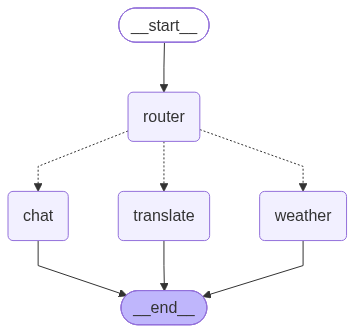

In [12]:

# 4.创建Graph，用Edge连接Node
builder = StateGraph(IntentState)

builder.add_node("router", intent_node)
builder.add_node("chat", chat_node)
builder.add_node("weather", weather_node)
builder.add_node("translate", translate_node)

builder.add_edge(START, "router")
builder.add_conditional_edges("router", intent_route)
builder.add_edge("chat", END)
builder.add_edge("weather", END)
builder.add_edge("translate", END)

graph = builder.compile()

display(Image(graph.get_graph(xray=True).draw_mermaid_png()))

In [13]:
# 5.测试
query = "你好"
result = graph.invoke({"messages": [HumanMessage(query)]})
print(f"query: {query}\nintent: {result['intent']}\nresult: {result['messages'][-1].text}")

query: 你好
intent: chat
result: 你好！很高兴见到你，有什么我可以帮忙的吗？无论是聊天、解答问题，还是需要一些建议，我都在这里。😊


In [14]:
query = "翻译一下: 虎哥 is handsome"
result = graph.invoke({"messages": [HumanMessage(query)]})
print(f"query: {query}\nintent: {result['intent']}\nresult: {result['messages'][-1].text}")

query: 翻译一下: 虎哥 is handsome
intent: translate
result: 虎哥很帅


In [15]:
query = "今天杭州天气如何"
result = graph.invoke({"messages": [HumanMessage(query)]})
print(f"query: {query}\nintent: {result['intent']}\nresult: {result['messages'][-1].text}")

query: 今天杭州天气如何
intent: weather
result: 今天天气晴朗，温度25°
